<a href="https://colab.research.google.com/github/Simpson69-il/DEEPLEARNING5THSEM/blob/main/EXPERIMENT%209/EX9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name: Mohd Shafique
Register Number: 24BAD074
Experiment: Generation of Synthetic Images Using GAN
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Dataset Information
Training images shape: (60000, 28, 28)
Testing images shape: (10000, 28, 28)
Image dimensions: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


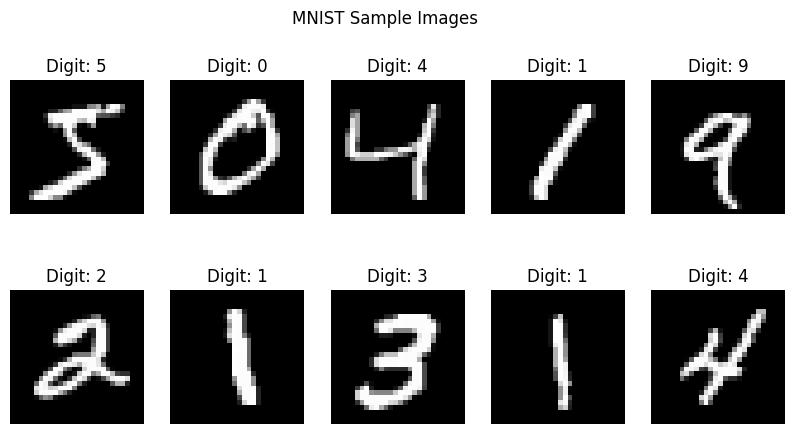


After Preprocessing:
Training shape: (60000, 28, 28, 1)
Normalized minimum: -1.0
Normalized maximum: 1.0

Dataset batching completed successfully!


In [ ]:

# EXPT NO: 8
# PART A: DATASET PREPARATION
# Student Name: Mohd Shafique
# Register Number: 24BAD074

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

print("Student Name: Mohd Shafique")
print("Register Number: 24BAD074")
print("Experiment: Generation of Synthetic Images Using GAN")

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset information
print("\nDataset Information")
print("Training images shape:", x_train.shape)
print("Testing images shape:", x_test.shape)
print("Image dimensions:", x_train.shape[1:])
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

# Display sample images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')

plt.suptitle("MNIST Sample Images")
plt.show()

# Normalize pixel values from [0, 255] to [-1, 1]
x_train = (x_train.astype('float32') - 127.5) / 127.5

# Reshape images
x_train = np.expand_dims(x_train, axis=-1)

print("\nAfter Preprocessing:")
print("Training shape:", x_train.shape)
print("Normalized minimum:", x_train.min())
print("Normalized maximum:", x_train.max())

# Prepare batches
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train
).shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)

print("\nDataset batching completed successfully!")


In [ ]:

# EXPT NO: 8
# PART B: GENERATOR AND DISCRIMINATOR
# Student: Mohd Shafique
# Register Number: 24BAD074

from tensorflow.keras import layers, Sequential

# Define latent dimension
LATENT_DIM = 100

# GENERATOR MODEL
generator = Sequential([
    layers.Input(shape=(LATENT_DIM,)),

    layers.Dense(7 * 7 * 256, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Reshape((7, 7, 256)),

    layers.Conv2DTranspose(
        128, kernel_size=5, strides=1,
        padding='same', use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(
        64, kernel_size=5, strides=2,
        padding='same', use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(
        1, kernel_size=5, strides=2,
        padding='same', activation='tanh'
    )
], name="Generator")

# DISCRIMINATOR MODEL
discriminator = Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64, kernel_size=5, strides=2, padding='same'
    ),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, kernel_size=5, strides=2, padding='same'
    ),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
], name="Discriminator")

# Display model summaries
print("GENERATOR MODEL SUMMARY")
generator.summary()

print("\nDISCRIMINATOR MODEL SUMMARY")
discriminator.summary()

# Create GAN by connecting Generator and Discriminator
discriminator.trainable = False

gan = Sequential([
    generator,
    discriminator
], name="GAN")

print("\nGAN MODEL SUMMARY")
gan.summary()

# Test Generator output
noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise, training=False)

print("\nGenerated image shape:", generated_image.shape)
print("Generator and Discriminator created successfully!")


GENERATOR MODEL SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

... (9 outputs left out)

 Total params: 2,543,810 (9.70 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 238,337 (931.00 KB)


Generated image shape: (1, 28, 28, 1)
Generator and Discriminator created successfully!


Starting GAN Training...
Epoch 1/10 | Generator Loss: 0.6599 | Discriminator Loss: 1.2698
Epoch 2/10 | Generator Loss: 0.7860 | Discriminator Loss: 1.2951


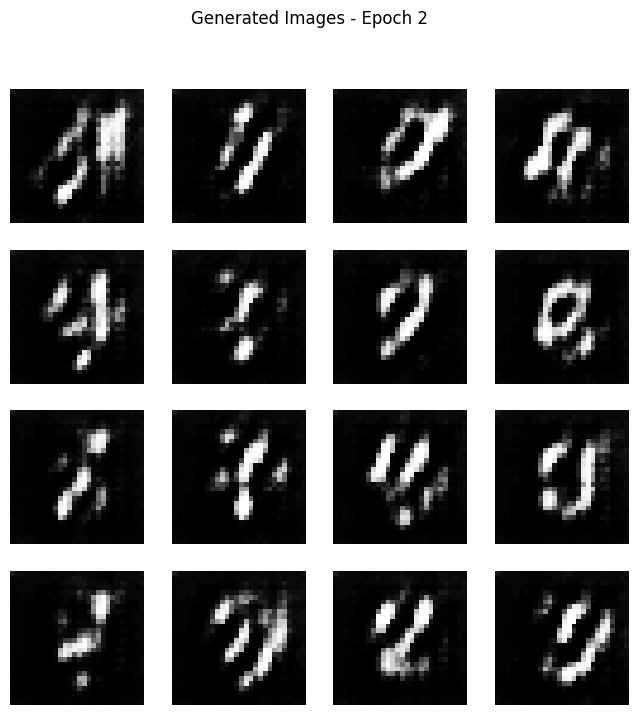

Epoch 3/10 | Generator Loss: 0.8069 | Discriminator Loss: 1.3347
Epoch 4/10 | Generator Loss: 0.8149 | Discriminator Loss: 1.3403


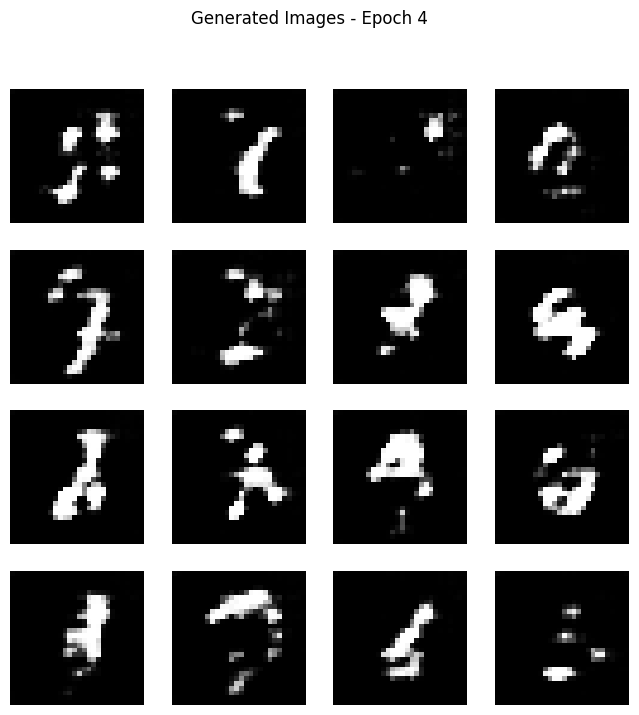

Epoch 5/10 | Generator Loss: 0.8005 | Discriminator Loss: 1.3411
Epoch 6/10 | Generator Loss: 0.7936 | Discriminator Loss: 1.3337


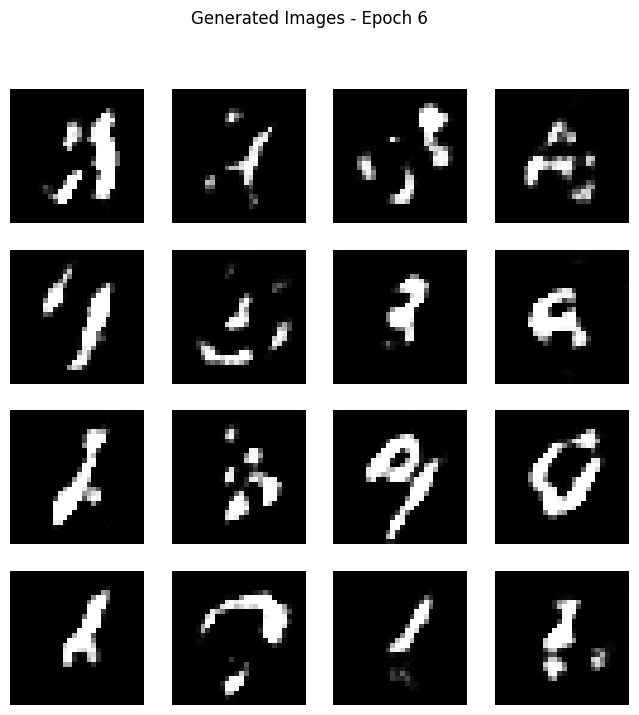

Epoch 7/10 | Generator Loss: 0.8101 | Discriminator Loss: 1.3278
Epoch 8/10 | Generator Loss: 0.8360 | Discriminator Loss: 1.3151


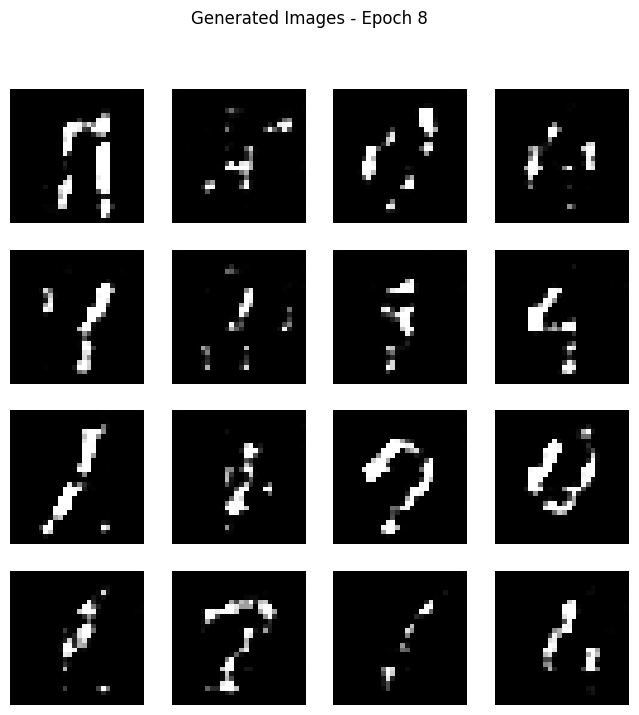

Epoch 9/10 | Generator Loss: 0.8288 | Discriminator Loss: 1.3150
Epoch 10/10 | Generator Loss: 0.8099 | Discriminator Loss: 1.3190


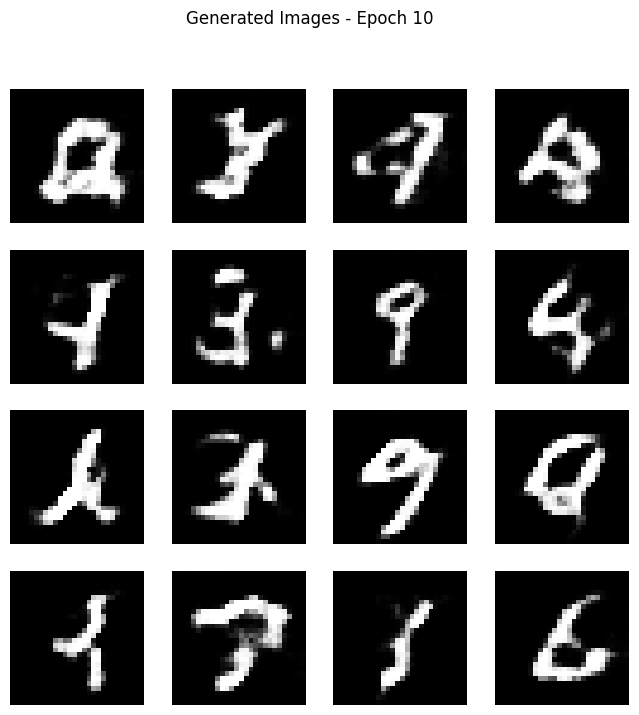

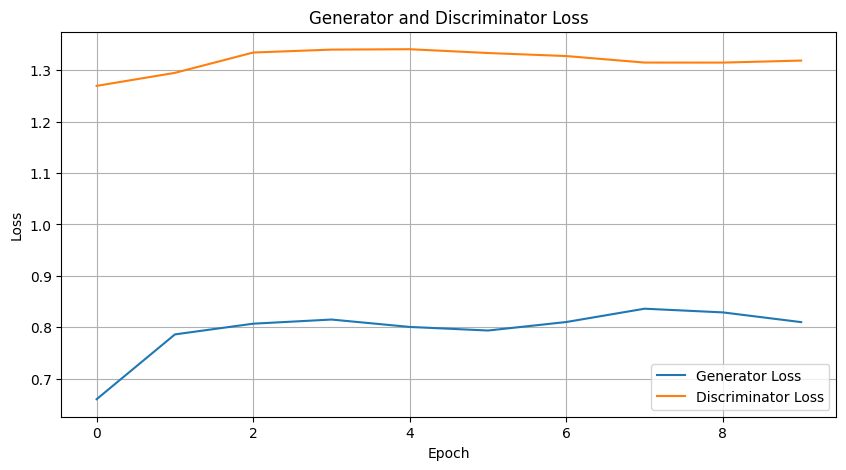


GAN Training Completed Successfully!


In [ ]:

# EXPT NO: 8
# PART C: GAN TRAINING AND PERFORMANCE MONITORING
# Student Name: Mohd Shafique
# Register Number: 24BAD074

import tensorflow as tf
import matplotlib.pyplot as plt

# Enable training for both models
generator.trainable = True
discriminator.trainable = True

# Loss function
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

# Generator loss
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

# Discriminator loss
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )

    return real_loss + fake_loss


# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)


# Training function
@tf.function
def train_step(images):

    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    # Train Discriminator
    with tf.GradientTape() as disc_tape:

        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)

        fake_output = discriminator(
            generated_images, training=True
        )

        d_loss = discriminator_loss(
            real_output, fake_output
        )

    disc_gradients = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # Train Generator
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape:

        generated_images = generator(noise, training=True)

        fake_output = discriminator(
            generated_images, training=False
        )

        g_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return g_loss, d_loss


# Function to display generated images
def generate_and_save_images(model, epoch, test_input):

    predictions = model(test_input, training=False)

    plt.figure(figsize=(8, 8))

    for i in range(16):
        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0] * 0.5 + 0.5,
            cmap='gray'
        )

        plt.axis('off')

    plt.suptitle("Generated Images - Epoch " + str(epoch))
    plt.show()


# Prepare smaller dataset for faster training
train_dataset = tf.data.Dataset.from_tensor_slices(
    x_train[:12000]
).shuffle(12000).batch(
    BATCH_SIZE, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

# Fixed random noise
seed = tf.random.normal([16, LATENT_DIM])

# Training parameters
EPOCHS = 10

gen_losses = []
disc_losses = []

print("Starting GAN Training...")

# Train GAN
for epoch in range(EPOCHS):

    total_g_loss = 0
    total_d_loss = 0
    batches = 0

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        total_g_loss += float(g_loss)
        total_d_loss += float(d_loss)
        batches += 1

    avg_g_loss = total_g_loss / batches
    avg_d_loss = total_d_loss / batches

    gen_losses.append(avg_g_loss)
    disc_losses.append(avg_d_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {avg_g_loss:.4f} | "
        f"Discriminator Loss: {avg_d_loss:.4f}"
    )

    # Display generated images every 2 epochs
    if (epoch + 1) % 2 == 0:
        generate_and_save_images(
            generator, epoch + 1, seed
        )


# Plot training losses
plt.figure(figsize=(10, 5))

plt.plot(gen_losses, label="Generator Loss")
plt.plot(disc_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator and Discriminator Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nGAN Training Completed Successfully!")


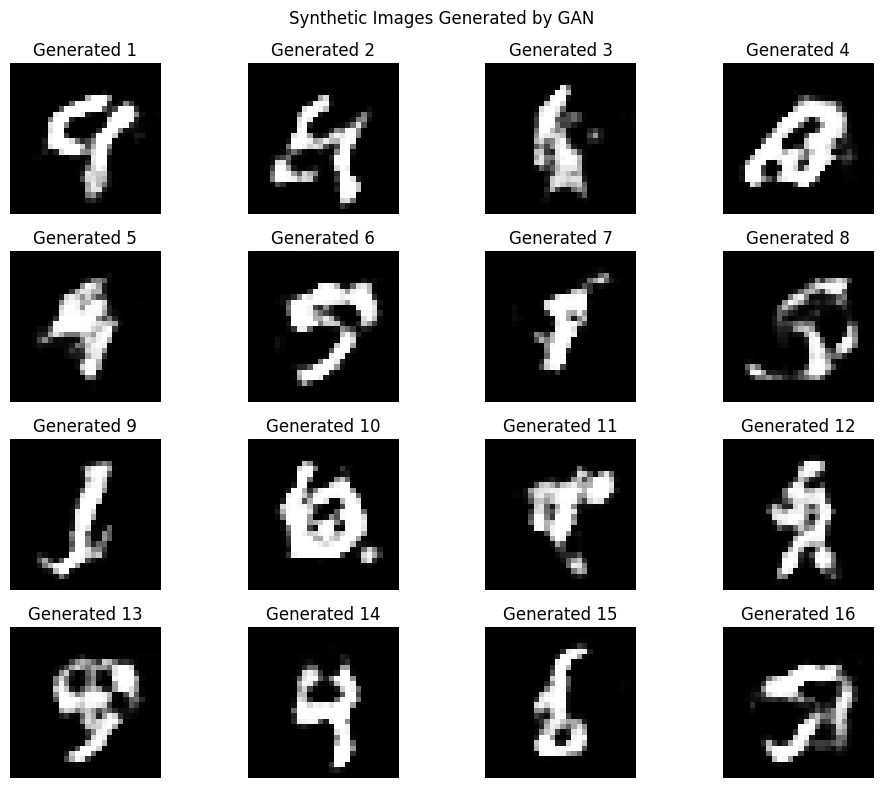

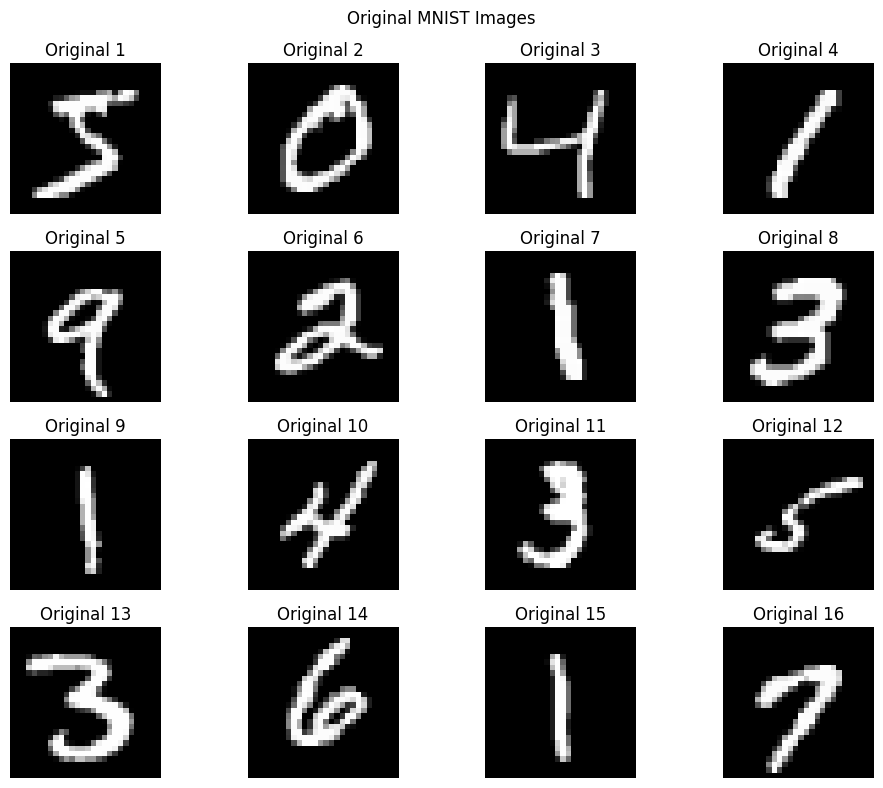

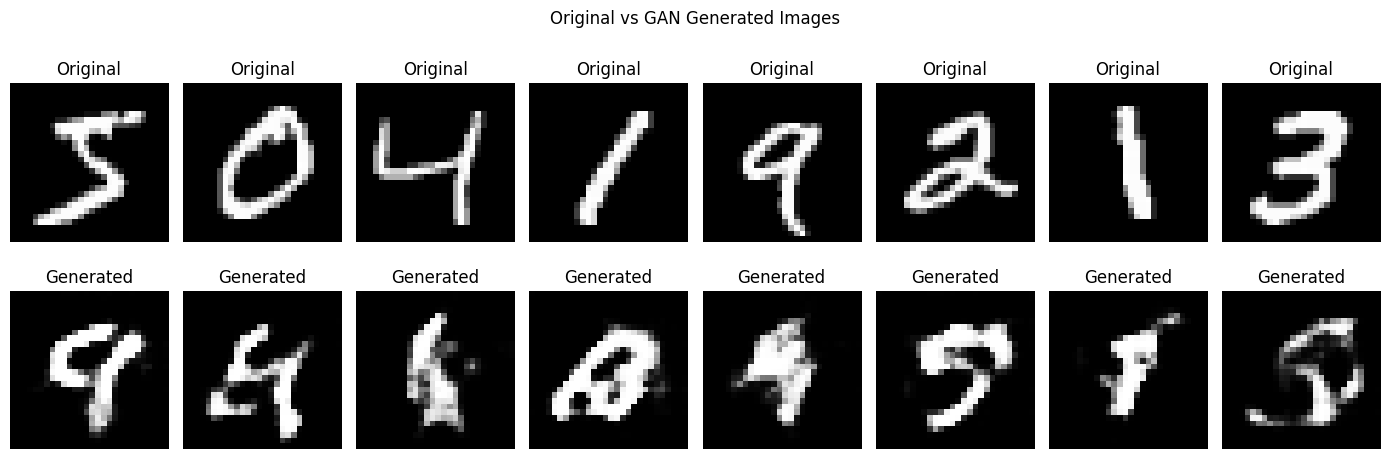

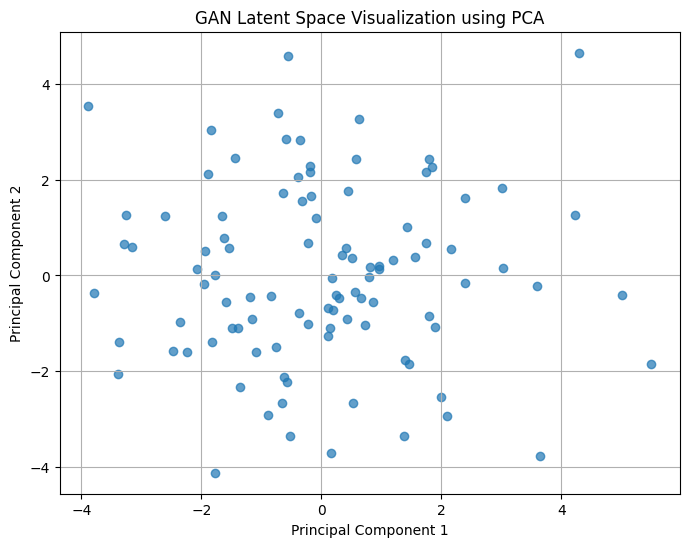

Student Name: Naveen B S
Register Number: 24BAD076

Synthetic image generation completed!
Original and generated images compared.
Latent space visualization completed.
GAN models saved successfully!


In [ ]:

# EXPT NO: 8
# PART D: IMAGE VISUALIZATION AND COMPARISON
# Student: Mohd Shafique
# Register Number: 24BAD074

from sklearn.decomposition import PCA

# Generate 16 synthetic images
noise = tf.random.normal([16, LATENT_DIM])

synthetic_images = generator(
    noise, training=False
)

# Display synthetic images
plt.figure(figsize=(10, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        synthetic_images[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )

    plt.title("Generated " + str(i + 1))
    plt.axis('off')

plt.suptitle("Synthetic Images Generated by GAN")
plt.tight_layout()
plt.show()


# Display original MNIST images
plt.figure(figsize=(10, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        x_train[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )

    plt.title("Original " + str(i + 1))
    plt.axis('off')

plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()


# Compare original and generated images
fig, axes = plt.subplots(2, 8, figsize=(14, 5))

for i in range(8):

    axes[0, i].imshow(
        x_train[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis('off')

    axes[1, i].imshow(
        synthetic_images[i, :, :, 0] * 0.5 + 0.5,
        cmap='gray'
    )
    axes[1, i].set_title("Generated")
    axes[1, i].axis('off')

plt.suptitle("Original vs GAN Generated Images")
plt.tight_layout()
plt.show()


# Latent space visualization using PCA
latent_vectors = tf.random.normal([100, LATENT_DIM])

pca = PCA(n_components=2)

latent_2d = pca.fit_transform(
    latent_vectors.numpy()
)

plt.figure(figsize=(8, 6))

plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("GAN Latent Space Visualization using PCA")
plt.grid(True)
plt.show()


# Save trained Generator
generator.save("GAN_Generator_24BAD076.keras")

# Save trained Discriminator
discriminator.save("GAN_Discriminator_24BAD076.keras")

print("Student Name: Naveen B S")
print("Register Number: 24BAD076")
print("\nSynthetic image generation completed!")
print("Original and generated images compared.")
print("Latent space visualization completed.")
print("GAN models saved successfully!")
